Our Proposition is:

 Low-income countries are more affected by climate-related disasters than high-income countries 



In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Climate change measured in CO2 emissisons 

climate_change_data = pd.read_csv("climate-change-raw-2021.csv", skiprows = 4)
climate_change_data = climate_change_data.drop(columns="Indicator Name")
climate_change_data = climate_change_data.drop(columns="Indicator Code")
climate_change_data.head()



,Country Name,Country Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Unnamed: 65
0,Aruba,ABW,50.776,50.761000,50.746000,50.730000,50.715000,50.700000,50.685000,50.670000,...,42.957000,42.990000,43.041000,43.108000,43.192000,43.293000,43.411000,43.546000,43.697000,NaN
1,Aruba,ABW,27525.000,28139.000000,28537.000000,28763.000000,28922.000000,29080.000000,29246.000000,29411.000000,...,44059.000000,44351.000000,44666.000000,44978.000000,45293.000000,45614.000000,45949.000000,46294.000000,46654.000000,NaN
2,Aruba,ABW,NaN,2.206183,1.404498,0.788835,0.551271,0.544810,0.569216,0.562594,...,0.543931,0.660561,0.707733,0.696090,0.697901,0.706219,0.731740,0.748028,0.774631,NaN
3,Aruba,ABW,54208.000,55434.000000,56234.000000,56699.000000,57029.000000,57357.000000,57702.000000,58044.000000,...,102565.000000,103165.000000,103776.000000,104339.000000,104865.000000,105361.000000,105846.000000,106310.000000,106766.000000,NaN
4,Aruba,ABW,NaN,2.236462,1.432843,0.823502,0.580334,0.573498,0.599694,0.590951,...,0.503385,0.583290,0.590508,0.541048,0.502860,0.471874,0.459266,0.437415,0.428017,NaN


In [4]:
# GDP measured in current international dollars (PPP) per capita.

gdp = pd.read_csv(
    "GDP-Per_capita-ppp.csv",
    skiprows=4
)
gdp = gdp.drop(columns=gdp.columns[gdp.columns.str.startswith("Unnamed")])
gdp = gdp.drop(columns = "Indicator Name")
gdp = gdp.drop(columns = "Indicator Code")
gdp.head()
gdp.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 68 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  266 non-null    object 
 1   Country Code  266 non-null    object 
 2   1960          0 non-null      float64
 3   1961          0 non-null      float64
 4   1962          0 non-null      float64
 5   1963          0 non-null      float64
 6   1964          0 non-null      float64
 7   1965          0 non-null      float64
 8   1966          0 non-null      float64
 9   1967          0 non-null      float64
 10  1968          0 non-null      float64
 11  1969          0 non-null      float64
 12  1970          0 non-null      float64
 13  1971          0 non-null      float64
 14  1972          0 non-null      float64
 15  1973          0 non-null      float64
 16  1974          0 non-null      float64
 17  1975          0 non-null      float64
 18  1976          0 non-null      

In [5]:
# Droughts, Floods, extreme temperatures (% of population, avg 1990-2009)
extreme_temp_data = pd.read_csv("API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv", skiprows = 4)
extreme_temp_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
gdp

,Country Name,Country Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,36117.535262,37524.914920,39287.059713,38554.716783,28733.604511,35207.170909,41863.273996,47521.876547,51712.153136,NaN
1,Africa Eastern and Southern,AFE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3639.496476,3843.028379,3727.710785,3804.533834,3707.033612,4022.277659,4359.591407,4496.744898,4635.125049,4840.265200
2,Afghanistan,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2213.181441,2335.795862,2432.276701,2583.485332,2561.981761,2144.166570,2122.659362,2203.537619,2236.199073,NaN
3,Africa Western and Central,AFW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4972.623859,5035.762391,5188.368000,5491.687935,5423.594405,5702.134886,6232.323014,6538.812038,6840.333882,7184.664483
4,Angola,AGO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7882.513705,8125.706394,8370.228758,8621.659308,7782.151534,8720.187687,9373.408309,9549.793139,9963.590209,10251.345706
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9157.046307,9380.940073,10018.738708,10861.053175,10532.505469,12362.421018,13948.685789,15817.432939,17890.360099,19263.326880
262,"Yemen, Rep.",YEM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,13519.323510,13738.438585,13347.363483,13361.485129,12671.086244,13681.954814,14746.710370,15212.260960,15478.645679,15905.679442
264,Zambia,ZMB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3313.351216,3391.627685,3442.273072,3361.397503,3157.300093,3503.034914,3840.115826,4080.355442,4221.013971,4379.261310


In [7]:
low_elevation_population = pd.read_csv('API_EN.POP.EL5M.ZS_DS2_en_csv_v2_30787.csv', skiprows = 4)
low_elevation_population

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",YEM,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
264,Zambia,ZMB,Population living in areas where elevation is ...,EN.POP.EL5M.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print(gdp[['Country Name', '2000']].head())
print(low_elevation_population[['Country Name', '2000']].head())

                  Country Name          2000
0                        Aruba  30245.706973
1  Africa Eastern and Southern   2170.537130
2                  Afghanistan    813.550256
3   Africa Western and Central   2460.633697
4                       Angola   3689.537808
                  Country Name      2000
0                        Aruba  5.126912
1  Africa Eastern and Southern  0.651664
2                  Afghanistan  0.000000
3   Africa Western and Central  3.129394
4                       Angola  0.671008


In [9]:
income = gdp[['Country Name', '2000']].copy()
income = income.rename(columns={'2000': 'GDP per Capita'})

elevation = low_elevation_population[['Country Name', '2000']].copy()
elevation = elevation.rename(columns={'2000': 'Low Elevation Population (%)'})

income['GDP per Capita'] = pd.to_numeric(income['GDP per Capita'], errors='coerce')
elevation['Low Elevation Population (%)'] = pd.to_numeric(elevation['Low Elevation Population (%)'], errors='coerce')

data = pd.merge(income, elevation, on='Country Name')
data = data.dropna()

top15 = data.nlargest(15, 'Low Elevation Population (%)')
top15 = top15.sort_values('Low Elevation Population (%)')

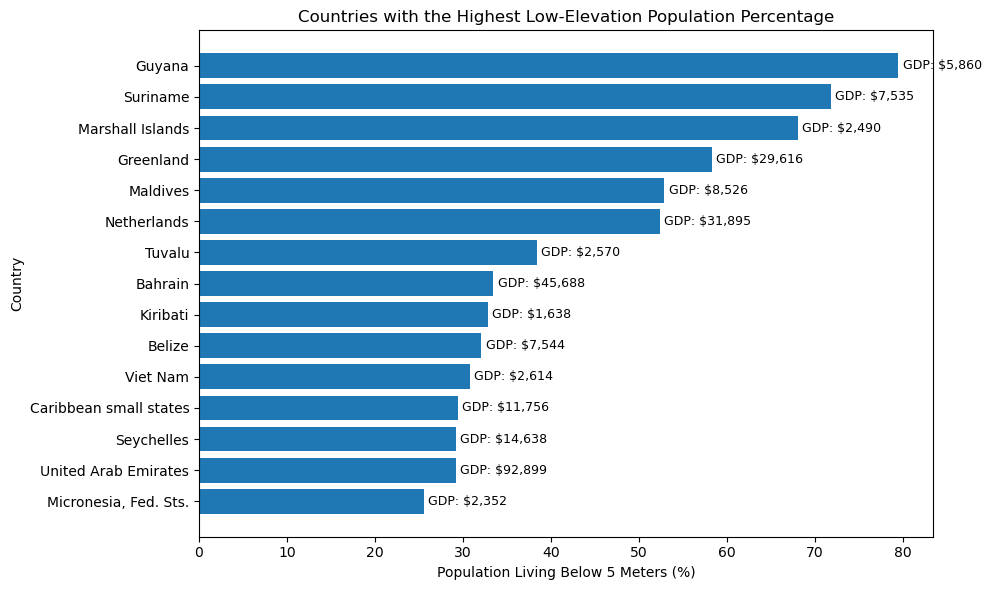

In [10]:
plot_data = top15.sort_values('Low Elevation Population (%)')

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_data['Country Name'],
    plot_data['Low Elevation Population (%)']
)

for i, row in enumerate(plot_data.itertuples()):
    plt.text(
        row[3] + 0.5,
        i,
        f"GDP: ${row[2]:,.0f}",
        va='center',
        fontsize=9
    )

plt.title('Countries with the Highest Low-Elevation Population Percentage')
plt.xlabel('Population Living Below 5 Meters (%)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Opposing Proposition: Climate-related risk are not exclusive to lower income countries; wealthy countries can also have a substantial population exposed to extreme climates. 

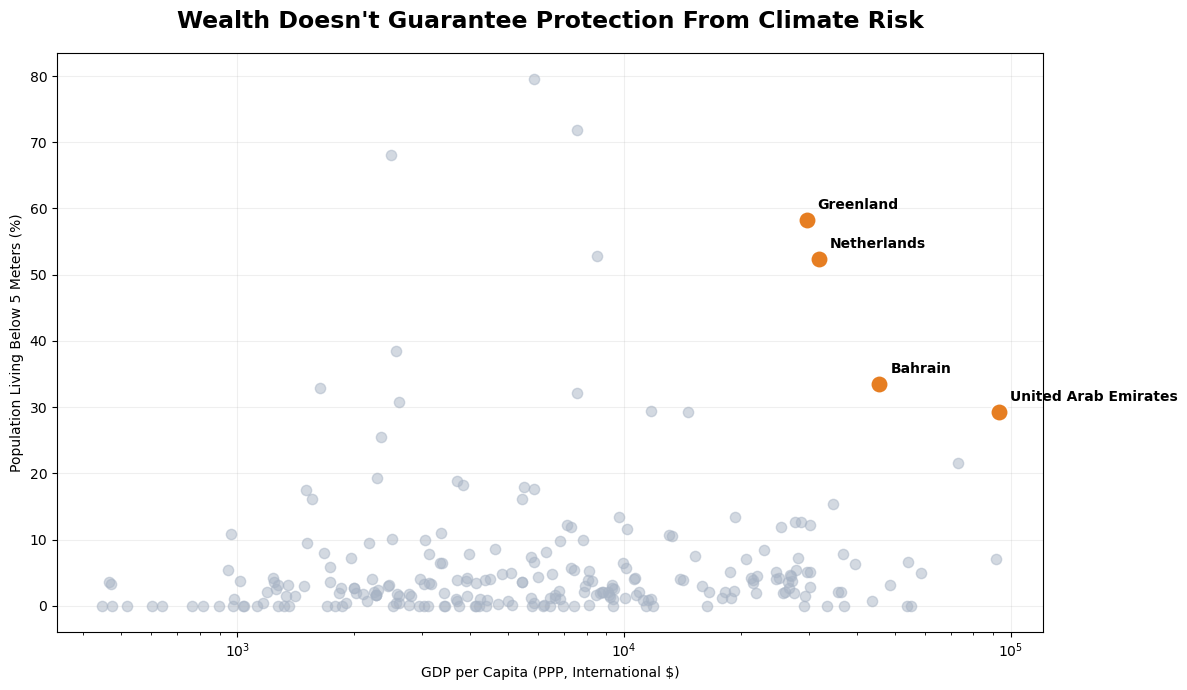

In [11]:
plot_df = data.copy()

highlights = [
    "Netherlands",
    "United Arab Emirates",
    "Bahrain",
    "Greenland"
]

plot_df["Highlighted"] = plot_df["Country Name"].isin(highlights)

fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    plot_df.loc[~plot_df["Highlighted"], "GDP per Capita"],
    plot_df.loc[~plot_df["Highlighted"], "Low Elevation Population (%)"],
    color="#A8B4C5",
    alpha=0.5,
    s=55
)

selected = plot_df[plot_df["Highlighted"]]

ax.scatter(
    selected["GDP per Capita"],
    selected["Low Elevation Population (%)"],
    color="#E67E22",
    s=160,
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

for _, row in selected.iterrows():
    ax.annotate(
        row["Country Name"],
        (row["GDP per Capita"], row["Low Elevation Population (%)"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xscale("log")
ax.set_xlabel("GDP per Capita (PPP, International $)")
ax.set_ylabel("Population Living Below 5 Meters (%)")

ax.set_title(
    "Wealth Doesn't Guarantee Protection From Climate Risk",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("randall_opposing_visualization.png", dpi=300, bbox_inches="tight")
plt.show()

### Opposing Visualization: Design Decisions 2

**Decision 1: Highlighted wealthy countries in orange**  
**Score: -1.0**

I highlighted wealthy countries while also keep the remaining the countries gray. This way I can show that the wealthy nations are facing climate exposure on the more extreme side and make their vulnerability seem more significant than the overall distribution generally suggest. 

**Decision 2: Use a logarithmic scale for GDP per capita**  
**Score: -0.5**

I also used a logarithmic scale to display the poorer countries with different income levels on the graph which compresses the differences within wealth making the wealthy and poorer countries appear closer together.

**Decision 3: Focus on population living below 5 meters**  
**Score: -1.5**

I used the low-eleveation precentages as an indicator of climate exposure. This will higlight the potential coastal vulnerability which can be a bit misleading because living at a lower elevation does not mean you typically experience greater damage from climate-related disasters.